***
<center>IMPORTS</center>


In [32]:
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import numpy as np
from sklearn.metrics import mean_squared_error

***
<center>Dwnd file</center>


In [9]:
file = pd.read_csv('data.csv', index_col='date', parse_dates=True)

infl = file['infl']

In [10]:
infl

date
2013-09-01    6.14
2013-10-01    6.27
2013-11-01    6.50
2013-12-01    6.47
2014-01-01    6.07
              ... 
2026-05-01    5.31
2026-06-01    6.02
2026-07-01    5.98
2026-08-01    6.33
2026-09-01    6.35
Name: infl, Length: 157, dtype: float64

***
Разделим данные на обучающую и тестовую выборки

- **train** — 09.2013–12.2024
- **test** — 01.2025–09.2026 

In [13]:
train = infl.loc[:'2024-12']
test = infl.loc['2025-01':]

In [14]:
print(len(train), len(test), len(train) + len(test))

136 21 157


Подбор p и q по ACF и PACF

In [16]:
d_train = train.diff().dropna()

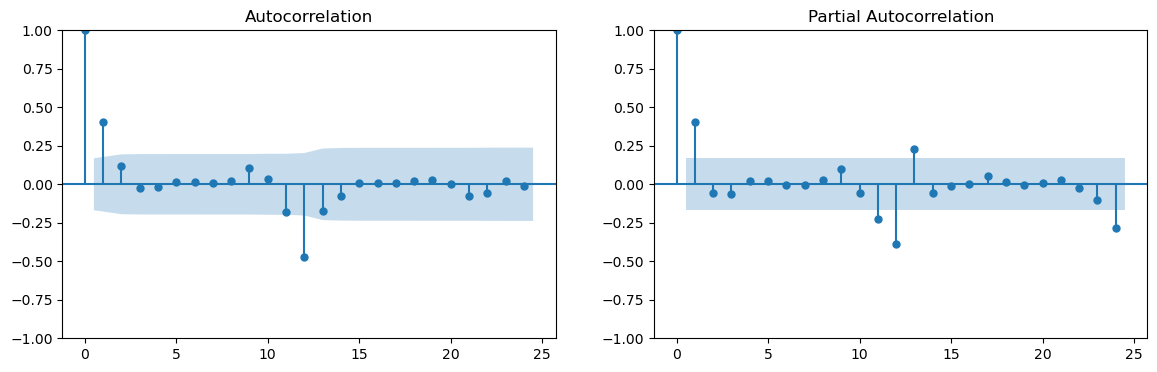

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(d_train, lags=24, ax=axes[0])
plot_pacf(d_train, lags=24, ax=axes[1])
plt.show()

- **Лаг 1** значим на обоих графиках (≈ +0.4): изменение инфляции в этом месяце
  похоже на изменение в прошлом — **инерция**.
- **Лаг 12** значим и отрицателен (ACF −0.47, PACF −0.43) — **эффект базы**:
  инфляция г/г сравнивает цены с тем же месяцем прошлого года, поэтому скачок
  год назад через 12 месяцев «выпадает» из расчёта и тянет показатель вниз.
  Лаги 11, 13 и 24 на PACF — эхо того же эффекта.
- Без учёта лага 12 оба графика обрываются после лага 1, поэтому чистого
  AR- или MA-процесса не видно

***
Обучение модели

In [19]:
model_1 = ARIMA(train, order = (1,1,1)).fit()
model_2 = ARIMA(train, order = (1,1,0)).fit()
model_3 = ARIMA(train, order = (0,1,1)).fit()


C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  

In [22]:
print(f'AIC for p = 1, q = 1: {model_1.aic}')
print(f'AIC for p = 1, q = 0: {model_2.aic}')
print(f'AIC for p = 0, q = 1: {model_3.aic}')

AIC for p = 1, q = 1: 401.8617219492892
AIC for p = 1, q = 0: 400.1678335464875
AIC for p = 0, q = 1: 402.45613922762846


***
Добавим сезонность

In [23]:
model_4 = ARIMA(train, order=(1, 1, 0), seasonal_order=(0, 0, 1, 12)).fit()
print(f'AIC for SARIMA(1,1,0)(0,0,1,12): {model_4.aic}')

AIC for SARIMA(1,1,0)(0,0,1,12): 333.84760838017985


C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\marr0\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


### Выбор модели

| Модель | AIC |
|---|---|
| ARIMA(1, 1, 1) | 401.9 |
| ARIMA(1, 1, 0) | 400.2 |
| ARIMA(0, 1, 1) | 402.5 |
| **SARIMA(1, 1, 0)(0, 0, 1, 12)** | **333.8** |

- Среди моделей без сезонной части AIC почти не отличаются (разница < 2.5),
  лучшая и самая простая — ARIMA(1, 1, 0): инерция от прошлого месяца.
- Добавление сезонной MA-части на лаге 12 снижает AIC на 66 — модель стала
  значительно лучше. Это подтверждает **эффект базы** в инфляции г/г,
  замеченный на ACF (лаг 12: −0.47).

**Выбрана модель SARIMA(1, 1, 0)(0, 0, 1, 12).**

In [25]:
# Прогноз SARIMA на 21 месяц вперёд

In [26]:
forecast = model_4.get_forecast(steps=len(test))
pred = forecast.predicted_mean     
ci = forecast.conf_int()

In [27]:
# Наивный прогноз: все месяцы = последнее значение train (12.2024)

In [28]:
naive = pd.Series(train.iloc[-1], index=test.index)

In [30]:
# Ошибки

In [33]:
rmse_sarima = np.sqrt(mean_squared_error(test, pred))
rmse_naive = np.sqrt(mean_squared_error(test, naive))

print(f'RMSE SARIMA: {rmse_sarima:.2f} п.п.')
print(f'RMSE наивный: {rmse_naive:.2f} п.п.')

RMSE SARIMA: 1.33 п.п.
RMSE наивный: 2.68 п.п.


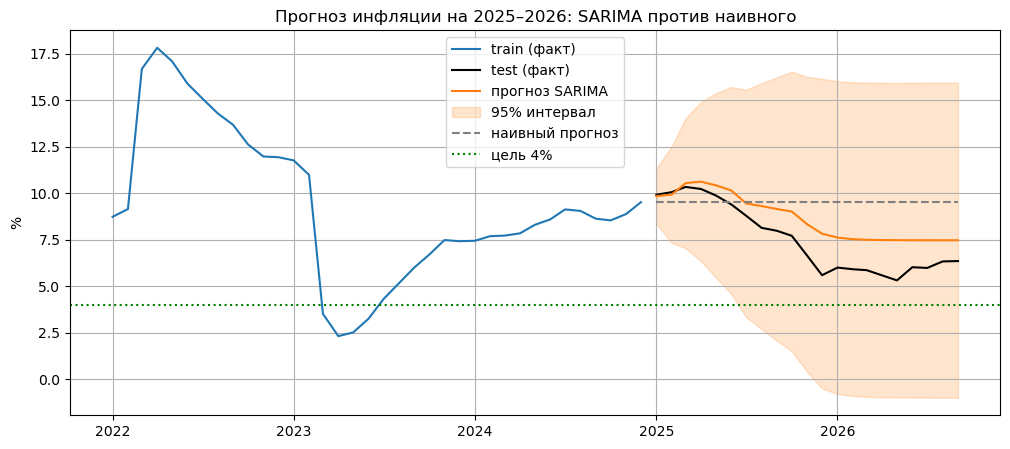

In [34]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(train.loc['2022':], label='train (факт)', color='tab:blue')
ax.plot(test, label='test (факт)', color='black')
ax.plot(pred, label='прогноз SARIMA', color='tab:orange')
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1],
                color='tab:orange', alpha=0.2, label='95% интервал')
ax.plot(naive, label='наивный прогноз', color='gray', linestyle='--')
ax.axhline(4, color='green', linestyle=':', label='цель 4%')

ax.set_title('Прогноз инфляции на 2025–2026: SARIMA против наивного')
ax.set_ylabel('%')
ax.legend()
ax.grid()
plt.show()

- **SARIMA ошибается в 2 раза меньше**, чем наивный прогноз.
- **Модель увидела разворот:** пик в начале 2025 г. и снижение инфляции после него.
- **Но снижение недооценила:** в 2026 г. прогноз ≈ 7.5%, а на деле 5.3–6.3%.
- **Ближайшие месяцы прогнозирует хорошо, дальше хуже:** через год прогноз
  становится ровной линией, а интервал неопределённости — очень широким.

**Почему так:** модель знает только прошлую инфляцию и не знает про ключевую ставку.
А ставка 21% (10.2024–05.2025) охлаждала экономику и ускорила снижение инфляции.